In [9]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [10]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure3"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [11]:
import os, glob, json, warnings
import numpy as np
import pandas as pd
from IPython.display import display

from scipy.stats import levene, t as student_t
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, matthews_corrcoef
import pingouin as pg
import matplotlib.pyplot as plt


# 1. Data loading

In [12]:
import os, glob
import pandas as pd

# ---- edit these to match your run ----
EXP        = "LLM_augmentation_experiment"     # your experiment folder under predictions/
TASK       = "binary"                       # "binary" | "multiclass" | "no_text"
MODEL_TYPE = "pytorch_mlp"                  # must match in run_name
MODALITIES = "Text_Embedding+Proteomics"    # run_name suffix after MODEL_TYPE
PRED_ROOT  = f"predictions/{EXP}/{TASK}"

def split_runname_by_model(run_name: str, model_type: str):
    """
    Expected run_name: {aug}_{llm}_{model_type}_{modalities}
    Returns (aug, llm, modalities) or None.
    """
    marker = f"_{model_type}_"
    if marker not in run_name:
        return None
    prefix, modalities = run_name.split(marker, 1)
    if "_" not in prefix:
        return None
    aug, llm = prefix.split("_", 1)
    return aug, llm, modalities

runs = []
for d in sorted(os.listdir(PRED_ROOT)):
    run_dir = os.path.join(PRED_ROOT, d)
    if not os.path.isdir(run_dir):
        continue
    parsed = split_runname_by_model(d, MODEL_TYPE)
    if parsed is None:
        continue
    aug, llm, mods = parsed
    if mods != MODALITIES:
        continue
    method = f"{aug}|{llm}"
    runs.append({"run_dir": run_dir, "run_name": d, "method": method})

assert runs, f"No runs found in {PRED_ROOT} for MODEL_TYPE={MODEL_TYPE} and MODALITIES={MODALITIES}"
runs


[{'run_dir': 'predictions/LLM_augmentation_experiment/binary/semantic_BERT_pytorch_mlp_Text_Embedding+Proteomics',
  'run_name': 'semantic_BERT_pytorch_mlp_Text_Embedding+Proteomics',
  'method': 'semantic|BERT'},
 {'run_dir': 'predictions/LLM_augmentation_experiment/binary/semantic_BioBERT_pytorch_mlp_Text_Embedding+Proteomics',
  'run_name': 'semantic_BioBERT_pytorch_mlp_Text_Embedding+Proteomics',
  'method': 'semantic|BioBERT'},
 {'run_dir': 'predictions/LLM_augmentation_experiment/binary/semantic_PubChemDeBERTa_pytorch_mlp_Text_Embedding+Proteomics',
  'run_name': 'semantic_PubChemDeBERTa_pytorch_mlp_Text_Embedding+Proteomics',
  'method': 'semantic|PubChemDeBERTa'},
 {'run_dir': 'predictions/LLM_augmentation_experiment/binary/sentence_BERT_pytorch_mlp_Text_Embedding+Proteomics',
  'run_name': 'sentence_BERT_pytorch_mlp_Text_Embedding+Proteomics',
  'method': 'sentence|BERT'},
 {'run_dir': 'predictions/LLM_augmentation_experiment/binary/sentence_BioBERT_pytorch_mlp_Text_Embedding+

In [13]:
def read_pairwise_one_run(run_dir):
    frames = []
    for pf in glob.glob(os.path.join(run_dir, "*.pkl")):
        if pf.endswith(".json"):
            continue
        try:
            df = pd.read_pickle(pf)
        except Exception:
            continue
        needed = {"True","ProbaPos","cv_iter","fold_idx","rep_idx"}
        if not needed.issubset(df.columns):
            continue
        # keep lightweight columns; add method later
        keep = ["True","Pred","ProbaPos","cv_iter","fold_idx","rep_idx"]
        frames.append(df[keep].copy())
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

all_rows = []
for r in runs:
    df = read_pairwise_one_run(r["run_dir"])
    if df.empty:
        continue
    df["method"] = r["method"]
    all_rows.append(df)

pairwise_df = pd.concat(all_rows, ignore_index=True)
pairwise_df["cv_iter"]  = pairwise_df["cv_iter"].astype(int)
pairwise_df["fold_idx"] = pairwise_df["fold_idx"].astype(int)
pairwise_df["rep_idx"]  = pairwise_df["rep_idx"].astype(int)
pairwise_df["resample_id"] = pairwise_df["cv_iter"].astype(str) + "-" + pairwise_df["fold_idx"].astype(str)

print(pairwise_df.shape)
pairwise_df.head()


(810000, 8)


,True,Pred,ProbaPos,cv_iter,fold_idx,rep_idx,method,resample_id
0,1,1,0.620264,0,0,0,semantic|BERT,0-0
1,1,1,0.760894,0,0,0,semantic|BERT,0-0
2,1,1,0.708766,0,0,0,semantic|BERT,0-0
3,1,1,0.601011,0,0,0,semantic|BERT,0-0
4,1,1,0.797918,0,0,0,semantic|BERT,0-0


In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef
)

# pairwise_df must already exist with:
# ['True','Pred','ProbaPos','cv_iter','fold_idx','method']

def safe_metrics_one_resample(y_true, proba, y_pred):
    out = {}
    # PR AUC / ROC AUC
    try:
        out['pr_auc'] = average_precision_score(y_true, proba)
    except Exception:
        out['pr_auc'] = np.nan
    try:
        out['roc_auc'] = roc_auc_score(y_true, proba)
    except Exception:
        out['roc_auc'] = np.nan
    # MCC (uses the provided hard predictions per your pipeline)
    try:
        out['mcc'] = matthews_corrcoef(y_true, y_pred)
    except Exception:
        out['mcc'] = np.nan
    return out

rows = []
for (m, it, fd), g in pairwise_df.groupby(['method','cv_iter','fold_idx'], sort=True):
    mets = safe_metrics_one_resample(
        g['True'].astype(int).values,
        g['ProbaPos'].astype(float).values,
        g['Pred'].astype(int).values
    )
    rows.append({
        'method': m,
        'cv_iter': int(it),
        'fold_idx': int(fd),
        'resample_id': f'{it}-{fd}',
        **mets
    })

resample_df = pd.DataFrame(rows)
# you should see ~25 rows/method (unless a degenerate fold was skipped)
print(resample_df.groupby('method').size().rename('n_resamples'))
resample_df.head()


method
semantic|BERT              25
semantic|BioBERT           25
semantic|PubChemDeBERTa    25
sentence|BERT              25
sentence|BioBERT           25
sentence|PubChemDeBERTa    25
word|BERT                  25
word|BioBERT               25
word|PubChemDeBERTa        25
Name: n_resamples, dtype: int64


,method,cv_iter,fold_idx,resample_id,pr_auc,roc_auc,mcc
0,semantic|BERT,0,0,0-0,0.785328,0.964479,0.606054
1,semantic|BERT,0,1,0-1,0.937108,0.988976,0.812801
2,semantic|BERT,0,2,0-2,0.826864,0.953493,0.670624
3,semantic|BERT,0,3,0-3,0.948046,0.992252,0.839493
4,semantic|BERT,0,4,0-4,0.928121,0.976344,0.870633


In [15]:
# --- build dataframe for rm-ANOVA / Tukey HSD (Pat Walters notebooks) ---

df_for_tests = resample_df.copy()

# 0..24 cycle id (outer×fold). Robust and matches repeated-measures design.
df_for_tests['cv_cycle'] = 5*df_for_tests['cv_iter'].astype(int) + df_for_tests['fold_idx'].astype(int)

# a label like the paper's 'scaffold' split; ours is compound-level
df_for_tests['split'] = 'compound'

# keep only what the helpers expect
metric_ls = ['roc_auc','pr_auc','mcc']
df_for_tests = df_for_tests[['cv_cycle','method','split'] + metric_ls].sort_values(
    ['method','cv_cycle']
).reset_index(drop=True)

# types
df_for_tests['method'] = df_for_tests['method'].astype('category')
df_for_tests['cv_cycle'] = df_for_tests['cv_cycle'].astype(int)

# balance check: every cycle must have all methods present (required for rm-ANOVA)
n_methods = df_for_tests['method'].nunique()
ok_cycles = (df_for_tests.groupby('cv_cycle')['method'].nunique() == n_methods)
bad_cycles = ok_cycles.index[~ok_cycles].tolist()
if bad_cycles:
    print(f"⚠️ Dropping {len(bad_cycles)} unbalanced cv_cycle(s): {bad_cycles[:5]} ...")
    df_for_tests = df_for_tests[df_for_tests['cv_cycle'].isin(ok_cycles[ok_cycles].index)].copy()

print("Rows per method:", df_for_tests.groupby('method').size().to_dict())
display(df_for_tests.head())


Rows per method: {'semantic|BERT': 25, 'semantic|BioBERT': 25, 'semantic|PubChemDeBERTa': 25, 'sentence|BERT': 25, 'sentence|BioBERT': 25, 'sentence|PubChemDeBERTa': 25, 'word|BERT': 25, 'word|BioBERT': 25, 'word|PubChemDeBERTa': 25}


/tmp/ipykernel_6260/2205695607.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("Rows per method:", df_for_tests.groupby('method').size().to_dict())


,cv_cycle,method,split,roc_auc,pr_auc,mcc
0,0,semantic|BERT,compound,0.964479,0.785328,0.606054
1,1,semantic|BERT,compound,0.988976,0.937108,0.812801
2,2,semantic|BERT,compound,0.953493,0.826864,0.670624
3,3,semantic|BERT,compound,0.992252,0.948046,0.839493
4,4,semantic|BERT,compound,0.976344,0.928121,0.870633


# 3. Export only required artifacts (main + supplementary)

This cell exports only what is needed for `figure3_combined.ipynb` and supplementary reporting:
- core tables (`resample_metrics.csv`, `rm_anova_input.csv`)
- RM-ANOVA summaries for `pr_auc`, `roc_auc`, `mcc`
- Bonferroni correction across metrics for omnibus RM-ANOVA (`alpha_bonf = 0.05 / 3`)
- Tukey adjusted p-value matrices and plots only for metrics passing the Bonferroni-gated omnibus test


/tmp/ipykernel_6260/3839411278.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_for_tests.groupby("method")[metric_ls]
/opt/conda/lib/python3.12/site-packages/pingouin/distribution.py:1004: RuntimeWarning: divide by zero encountered in scalar divide
  W = np.prod(eig) / (eig.sum() / d) ** d


Bonferroni omnibus threshold across metrics: alpha_bonf=0.016667
    metric  rm_anova_p  omnibus_sig_bonf
0   pr_auc    0.001960              True
1  roc_auc    0.019996             False
2      mcc    0.017468             False


/tmp/ipykernel_6260/3839411278.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = plot_df.groupby("var_tag")[metric].mean().sort_values(ascending=False)
/mnt/nas/PhD/Code/Ms_paint/code_repository/notebooks/analysis/model_comparison.py:85: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_means = df.groupby(group_col).mean(numeric_only=True)
/tmp/ipykernel_6260/3839411278.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


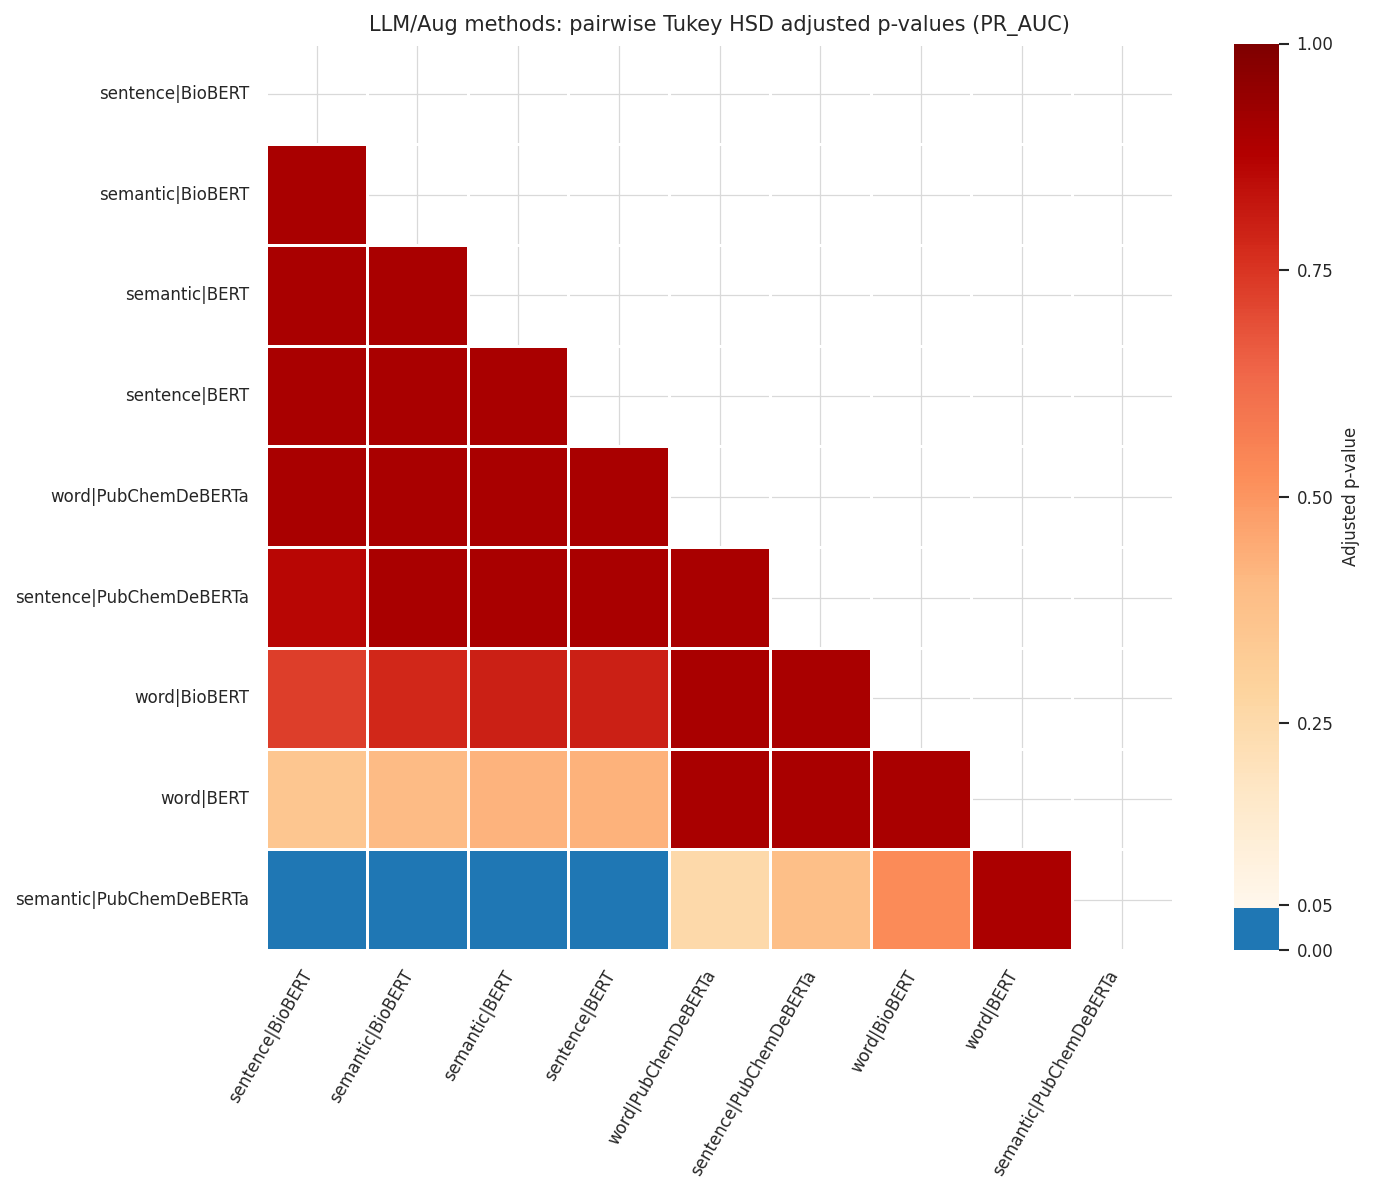

/tmp/ipykernel_6260/3839411278.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = plot_df.groupby("var_tag")[metric].mean().sort_values(ascending=False)
/tmp/ipykernel_6260/3839411278.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Omnibus not significant for roc_auc: RM-ANOVA p=2.000e-02 >= alpha_bonf=1.667e-02; boxplot exported with neutral (non-significant) colors only.


/tmp/ipykernel_6260/3839411278.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = plot_df.groupby("var_tag")[metric].mean().sort_values(ascending=False)
/tmp/ipykernel_6260/3839411278.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Omnibus not significant for mcc: RM-ANOVA p=1.747e-02 >= alpha_bonf=1.667e-02; boxplot exported with neutral (non-significant) colors only.
Saved analysis artifacts to: analysis_exports/LLM_augmentation_experiment_binary_pytorch_mlp_Text_Embedding-Proteomics


In [16]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pingouin as pg
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from analysis.model_comparison import rm_tukey_hsd, plot_pairwise_q_heatmap_sig

OUTDIR = Path(f"analysis_exports/{EXP}_{TASK}_{MODEL_TYPE}_{MODALITIES.replace('+','-')}")
OUTDIR.mkdir(parents=True, exist_ok=True)

# Core tables consumed downstream
resample_df.to_csv(OUTDIR / "resample_metrics.csv", index=False)
df_for_tests.to_csv(OUTDIR / "rm_anova_input.csv", index=False)

(
    df_for_tests.groupby("method")[metric_ls]
    .agg(["mean", "std", "median", "min", "max", "count"])
).to_csv(OUTDIR / "method_descriptives.csv")

metrics_eval = ["pr_auc", "roc_auc", "mcc"]
alpha_family = 0.05
alpha_bonf = alpha_family / len(metrics_eval)
alpha_tukey = 0.05

anova_rows = []
for metric in metrics_eval:
    # RM-ANOVA table
    aov = pg.rm_anova(dv=metric, within="method", subject="cv_cycle", data=df_for_tests, detailed=True)
    aov.to_csv(OUTDIR / f"anova_{metric}.csv", index=False)
    if "p-gg-corr" in aov.columns:
        p_rm = float(aov.loc[aov["Source"] == "method", "p-gg-corr"].iloc[0])
    else:
        p_rm = float(aov.loc[aov["Source"] == "method", "p-unc"].iloc[0])

    omnibus_sig_bonf = bool(np.isfinite(p_rm) and (p_rm < alpha_bonf))
    anova_rows.append(
        {
            "metric": metric,
            "rm_anova_p": p_rm,
            "alpha_family": alpha_family,
            "alpha_bonf": alpha_bonf,
            "omnibus_sig_bonf": omnibus_sig_bonf,
        }
    )

anova_summary = pd.DataFrame(anova_rows)
anova_summary.to_csv(OUTDIR / "anova_summary.csv", index=False)
print(f"Bonferroni omnibus threshold across metrics: alpha_bonf={alpha_bonf:.6f}")
print(anova_summary[["metric", "rm_anova_p", "omnibus_sig_bonf"]])

# Step 3 (JCIM recommendation):
# - Always export descriptive boxplots for all metrics
# - Apply Tukey significance coloring/heatmaps only when Bonferroni-gated omnibus RM-ANOVA is significant
for row in anova_rows:
    metric = row["metric"]
    p_rm = row["rm_anova_p"]
    omnibus_sig = row["omnibus_sig_bonf"]

    # Prepare data for boxplots (always)
    plot_df = df_for_tests[["cv_cycle", "method", metric]].rename(columns={"method": "var_tag"}).copy()
    means = plot_df.groupby("var_tag")[metric].mean().sort_values(ascending=False)
    order = means.index.tolist()
    best = order[0]
    best_mean = float(means.iloc[0])

    # Compute Tukey only for omnibus-significant metrics
    tukey_pmat = None
    if omnibus_sig:
        tukey_tab, df_means, df_means_diff, tukey_pmat = rm_tukey_hsd(
            df_for_tests, metric, group_col="method", alpha=alpha_tukey
        )
        tukey_tab.to_csv(OUTDIR / f"tukey_{metric}_pairs.csv", index=False)
        df_means.reset_index().to_csv(OUTDIR / f"tukey_{metric}_means.csv", index=False)
        df_means_diff.to_csv(OUTDIR / f"tukey_{metric}_mean_diffs.csv")
        tukey_pmat.to_csv(OUTDIR / f"tukey_{metric}_pvals_matrix.csv")
    else:
        print(
            f"Omnibus not significant for {metric}: RM-ANOVA p={p_rm:.3e} >= alpha_bonf={alpha_bonf:.3e}; "
            "boxplot exported with neutral (non-significant) colors only."
        )

    # Boxplot coloring
    palette = []
    for tag in order:
        if tag == best:
            palette.append("#1f77b4")
        else:
            if omnibus_sig and (tukey_pmat is not None):
                q = tukey_pmat.loc[best, tag] if (best in tukey_pmat.index and tag in tukey_pmat.columns) else np.nan
                if (not np.isnan(q)) and (q < alpha_tukey) and (means.loc[tag] < best_mean):
                    palette.append("#c45c5c")
                else:
                    palette.append("#9e9e9e")
            else:
                # Omnibus not significant: do not show pairwise significant colors
                palette.append("#9e9e9e")

    apply_style()
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(
        data=plot_df,
        x="var_tag",
        y=metric,
        order=order,
        palette=palette,
        whis=1.5,
        fliersize=2,
        showfliers=False,
        ax=ax,
    )
    ax.axhline(best_mean, color="#1f77b4", linestyle="--", linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel(metric.upper())
    if omnibus_sig:
        title_suffix = f"(RM-ANOVA p={p_rm:.1e}, Bonf alpha={alpha_bonf:.2e})"
    else:
        title_suffix = f"(RM-ANOVA p={p_rm:.1e}, Bonf alpha={alpha_bonf:.2e}; omnibus NS)"
    ax.set_title(f"LLM/Aug methods: {metric.upper()} by method {title_suffix}")
    ax.tick_params(axis="x", rotation=45)
    if omnibus_sig:
        handles = [
            Patch(facecolor="#1f77b4", edgecolor="none", label="Best"),
            Patch(facecolor="#9e9e9e", edgecolor="none", label=f"Not statistically different vs best (Tukey p-adj>={alpha_tukey})"),
            Patch(facecolor="#c45c5c", edgecolor="none", label=f"Significantly worse (Tukey p-adj<{alpha_tukey})"),
            Line2D([0], [0], color="#1f77b4", lw=1, ls="--", label="Best mean"),
        ]
    else:
        handles = [
            Patch(facecolor="#1f77b4", edgecolor="none", label="Best (descriptive)"),
            Patch(facecolor="#9e9e9e", edgecolor="none", label="All others (no pairwise significance shown)"),
            Line2D([0], [0], color="#1f77b4", lw=1, ls="--", label="Best mean"),
        ]
    ax.legend(handles=handles, frameon=False, loc="lower left")
    plt.tight_layout()
    save_figure(fig, OUTDIR / f"methods_box_tukey_{metric}.png")
    plt.close(fig)

    # Pairwise Tukey HSD-adjusted p-value heatmap only for omnibus-significant metrics
    if omnibus_sig and (tukey_pmat is not None):
        plot_pairwise_q_heatmap_sig(
            pval_matrix=tukey_pmat,
            means=means,
            alpha=alpha_tukey,
            title=f"LLM/Aug methods: pairwise Tukey HSD adjusted p-values ({metric.upper()})",
            annotate=False,
            savepath=str(OUTDIR / f"methods_pairwise_tukey_{metric}.svg"),
        )
        plt.close("all")

print("Saved analysis artifacts to:", OUTDIR)
